<a href="https://colab.research.google.com/github/Jaggiiii/transformers/blob/main/mplement_attention_from_scratch.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
print("hi")

hi


Raw scores:
 [[1.25 0.1  1.3  0.25]
 [0.1  1.04 0.3  0.96]
 [1.3  0.3  1.65 0.47]
 [0.25 0.96 0.47 0.91]]

Scaled scores:
 [[0.722 0.058 0.751 0.144]
 [0.058 0.6   0.173 0.554]
 [0.751 0.173 0.953 0.271]
 [0.144 0.554 0.271 0.525]]

Attention weights:
 [[0.322 0.166 0.331 0.181]
 [0.182 0.314 0.205 0.299]
 [0.294 0.165 0.359 0.182]
 [0.196 0.295 0.222 0.287]]

Attention output:
 [[0.605 0.362 0.58 ]
 [0.376 0.604 0.448]
 [0.6   0.365 0.594]
 [0.402 0.575 0.465]]


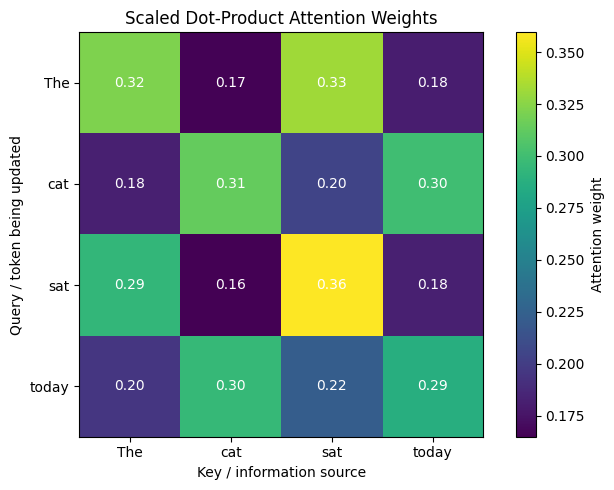


All sanity checks passed.


In [2]:

import numpy as np
import matplotlib.pyplot as plt

# Four token representations, each with dimension 3.
# Simplified demonstration: use the same vectors for Q, K and V.
X = np.array([
    [1.0, 0.0, 0.5],  # The
    [0.0, 1.0, 0.2],  # cat
    [0.8, 0.1, 1.0],  # sat
    [0.1, 0.9, 0.3],  # today
])

tokens = ["The", "cat", "sat", "today"]

Q = X
K = X
V = X

# Step 1: Calculate raw attention scores
scores = Q @ K.T

# Step 2: Scale by sqrt(key dimension)
d_k = K.shape[1]
scaled_scores = scores / np.sqrt(d_k)

# Step 3: Softmax, computed stably
shifted_scores = scaled_scores - np.max(
    scaled_scores, axis=1, keepdims=True
)
exp_scores = np.exp(shifted_scores)

attention_weights = exp_scores / np.sum(
    exp_scores, axis=1, keepdims=True
)

# Step 4: Weighted sum of values
output = attention_weights @ V

print("Raw scores:\n", np.round(scores, 3))
print("\nScaled scores:\n", np.round(scaled_scores, 3))
print("\nAttention weights:\n", np.round(attention_weights, 3))
print("\nAttention output:\n", np.round(output, 3))

# Step 5: Visualize attention weights
plt.figure(figsize=(7, 5))
plt.imshow(attention_weights, cmap="viridis")
plt.colorbar(label="Attention weight")

plt.xticks(range(len(tokens)), tokens)
plt.yticks(range(len(tokens)), tokens)
plt.xlabel("Key / information source")
plt.ylabel("Query / token being updated")
plt.title("Scaled Dot-Product Attention Weights")

for i in range(len(tokens)):
    for j in range(len(tokens)):
        plt.text(
            j, i, f"{attention_weights[i, j]:.2f}",
            ha="center", va="center", color="white"
        )

plt.tight_layout()
plt.show()

# Sanity checks
assert attention_weights.shape == (4, 4)
assert output.shape == X.shape
assert np.allclose(attention_weights.sum(axis=1), 1.0)

print("\nAll sanity checks passed.")
